In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("D:\Data Analytics\Projects\Anti-Money Laundering (AML) transaction monitoring\HI-Small_Trans.csv")
df.head(5)

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,01-09-2022 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,01-09-2022 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,01-09-2022 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,01-09-2022 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,01-09-2022 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


**Phase 1 — Understanding data**

1. How many rows and columns are there, and what are the data types?

In [3]:
df.shape

(1048575, 11)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Timestamp           1048575 non-null  object 
 1   From Bank           1048575 non-null  int64  
 2   Account             1048575 non-null  object 
 3   To Bank             1048575 non-null  int64  
 4   Account.1           1048575 non-null  object 
 5   Amount Received     1048575 non-null  float64
 6   Receiving Currency  1048575 non-null  object 
 7   Amount Paid         1048575 non-null  float64
 8   Payment Currency    1048575 non-null  object 
 9   Payment Format      1048575 non-null  object 
 10  Is Laundering       1048575 non-null  int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 88.0+ MB


In [9]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   Timestamp           1048575 non-null  datetime64[ns]
 1   From Bank           1048575 non-null  int64         
 2   Account             1048575 non-null  object        
 3   To Bank             1048575 non-null  int64         
 4   Account.1           1048575 non-null  object        
 5   Amount Received     1048575 non-null  float64       
 6   Receiving Currency  1048575 non-null  object        
 7   Amount Paid         1048575 non-null  float64       
 8   Payment Currency    1048575 non-null  object        
 9   Payment Format      1048575 non-null  object        
 10  Is Laundering       1048575 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 88.0+ MB


2. Are there missing values, duplicate records, or invalid values?

In [5]:
df.isnull().sum()

Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64

In [6]:
df[df.duplicated]

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
863295,01-09-2022 16:20,12004,800C927C1,12004,800C927C0,0.000008,Bitcoin,0.080000,Euro,ACH,0
863296,01-09-2022 16:20,12004,800C927C1,220,813D8C1E1,0.000008,Bitcoin,0.000008,Bitcoin,Bitcoin,0


In [11]:
df = df.drop_duplicates()

In [12]:
df[df.duplicated]

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering


3. What is the date range covered by the transactions?

In [14]:
start_dt = df['Timestamp'].min()
end_dt = df['Timestamp'].max()

print(f'Date range is : {start_dt} to {end_dt}')

Date range is : 2022-01-09 00:00:00 to 2022-09-09 08:29:00


4. What percentage of transactions are labelled laundering versus non-laundering?

In [25]:
laundering_count = (df['Is Laundering'] == 1).sum()
non_laundering_count = (df['Is Laundering'] == 0).sum()
total_transactions = len(df)

laundering_per = (laundering_count / total_transactions) * 100
non_laundering_per = (non_laundering_count / total_transactions) * 100

print(f"Laundering percentage: {laundering_per:.4f}%")
print(f"Non-laundering percentage: {non_laundering_per:.4f}%")

Laundering percentage: 0.0587%
Non-laundering percentage: 99.9413%


**Phase 2 — Explore transaction patterns**

5. What do transaction amounts look like? Are there extreme values or outliers?

In [5]:
df[['Amount Received', 'Amount Paid']]

,Amount Received,Amount Paid
0,3697.34,3697.34
1,0.01,0.01
2,14675.57,14675.57
3,2806.97,2806.97
4,36682.97,36682.97
...,...,...
1048570,27186.66,27186.66
1048571,132355.38,132355.38
1048572,3764.12,3764.12
1048573,892.20,892.20


In [21]:
df[['Amount Received', 'Amount Paid']].describe().style.format("{:,.2f}")

,Amount Received,Amount Paid
count,"1,048,575.00","1,048,575.00"
mean,"7,137,529.80","5,917,423.87"
std,"602,999,068.49","469,306,005.56"
min,0.00,0.00
25%,101.19,101.92
50%,"1,925.45","1,928.91"
75%,"24,768.46","24,693.39"
max,"284,000,000,000.00","284,000,000,000.00"


*Finding outliers*

In [7]:
amount_paid_q1 = df['Amount Paid'].quantile(0.25)
amount_paid_q3 = df['Amount Paid'].quantile(0.75)
print('Amount paid')
print(f'Q1: {amount_paid_q1} \nQ2: {amount_paid_q3}')
amount_recieved_q1 = df['Amount Received'].quantile(0.25)
amount_recieved_q3 = df['Amount Received'].quantile(0.75)
print('Amount recieved')
print(f'Q1: {amount_recieved_q1} \nQ2: {amount_recieved_q3}')

Amount paid
Q1: 101.92 
Q2: 24693.39
Amount recieved
Q1: 101.195 
Q2: 24768.46


In [8]:
amount_paid_iqr = amount_paid_q3-amount_paid_q1
amount_recieved_iqr = amount_recieved_q3-amount_recieved_q1

print(f'IQR of Amount paid: {amount_paid_iqr}')
print(f'IQR of Amount recieved: {amount_recieved_iqr}')

IQR of Amount paid: 24591.47
IQR of Amount recieved: 24667.265


In [9]:
'''Lower bound = Q1 - 1.5 x IQR*
Upper bound = Q3 + 1.5 x IQR'''

amount_paid_lb = amount_paid_q1-1.5*amount_paid_iqr
amount_paid_ub = amount_paid_q3+1.5*amount_paid_iqr
print('Amount paid')
print(f'Lower bound: {amount_paid_lb} \nUpper bound{amount_paid_ub}')

amount_recieved_lb = amount_recieved_q1-1.5*amount_recieved_iqr
amount_recieved_ub = amount_recieved_q3+1.5*amount_recieved_iqr
print('Amount recieved')
print(f'Lower bound: {amount_recieved_lb} \nUpper bound{amount_recieved_ub}')

Amount paid
Lower bound: -36785.285 
Upper bound61580.595
Amount recieved
Lower bound: -36899.7025 
Upper bound61769.3575


In [13]:
outlier_count1 = (df['Amount Received']>amount_recieved_ub).sum()
print(f'Outliers for the column "Amount Recieved" are: {outlier_count1}')

outlier_count2 = (df['Amount Paid']>amount_paid_ub).sum()
print(f'Outliers for the column "Amount Paid" are: {outlier_count2}')

Outliers for the column "Amount Recieved" are: 197322
Outliers for the column "Amount Paid" are: 197081


In [14]:
total_transactions = len(df)

print(f"Amount Received: {outlier_count1 / total_transactions * 100:.2f}%")
print(f"Amount Paid: {outlier_count2 / total_transactions * 100:.2f}%")

Amount Received: 18.82%
Amount Paid: 18.80%


6. How do transaction amounts differ between laundering-labelled and other transactions?

In [7]:
df[df["Is Laundering"]==0].describe().style.format("{:,.2f}")

,From Bank,To Bank,Amount Received,Amount Paid,Is Laundering
count,"1,047,960.00","1,047,960.00","1,047,960.00","1,047,960.00","1,047,960.00"
mean,"58,838.82","70,832.75","6,996,829.06","5,776,007.11",0.00
std,"90,989.89","90,900.80","593,922,168.96","457,492,423.14",0.00
min,1.00,1.00,0.00,0.00,0.00
25%,"1,198.00","5,140.00",101.01,101.69,0.00
50%,"15,010.00","22,164.00","1,922.54","1,925.72",0.00
75%,"110,836.00","125,607.00","24,776.33","24,702.94",0.00
max,"356,300.00","356,294.00","284,000,000,000.00","284,000,000,000.00",0.00


In [8]:
df[df["Is Laundering"]==1].describe().style.format("{:,.2f}")

,From Bank,To Bank,Amount Received,Amount Paid,Is Laundering
count,615.00,615.00,615.00,615.00,615.00
mean,"46,245.86","48,134.42","246,891,582.12","246,891,582.12",1.00
std,"75,703.66","72,732.75","4,341,606,726.11","4,341,606,726.11",0.00
min,1.00,1.00,0.27,0.27,1.00
25%,70.00,"1,420.00","2,854.43","2,854.43",1.00
50%,"5,464.00","15,723.00","8,784.93","8,784.93",1.00
75%,"38,622.00","48,308.00","17,718.57","17,718.57",1.00
max,"254,355.00","254,242.00","84,853,144,180.00","84,853,144,180.00",1.00


*1. For Amount Received, which group has the higher mean?
Is Laundering = 1*

*2. For Amount Received, which group has the higher median (50%)?*
*Is Laundering = 1*

*3. For Amount Paid, which group has the higher median (50%)?
Is Laundering = 1*

*4. In either group, is the mean much larger than the median?
Yes*

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

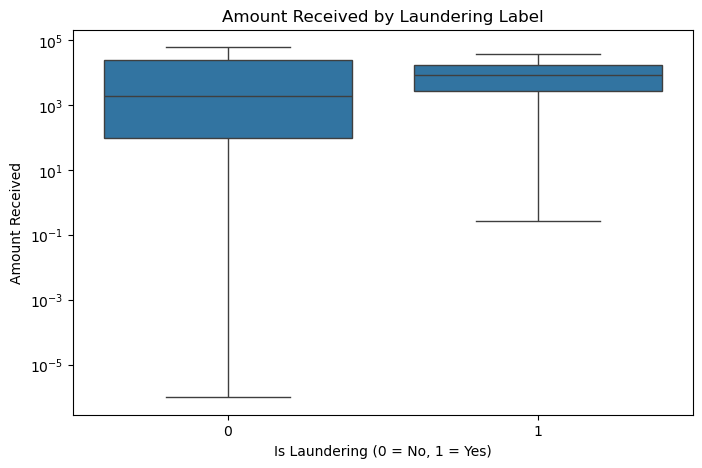

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(data = df, x = "Is Laundering", y = "Amount Received", showfliers = False)
plt.title("Amount Received by Laundering Label")
plt.xlabel("Is Laundering (0 = No, 1 = Yes)")
plt.ylabel("Amount Received")
plt.yscale("log")
plt.show()

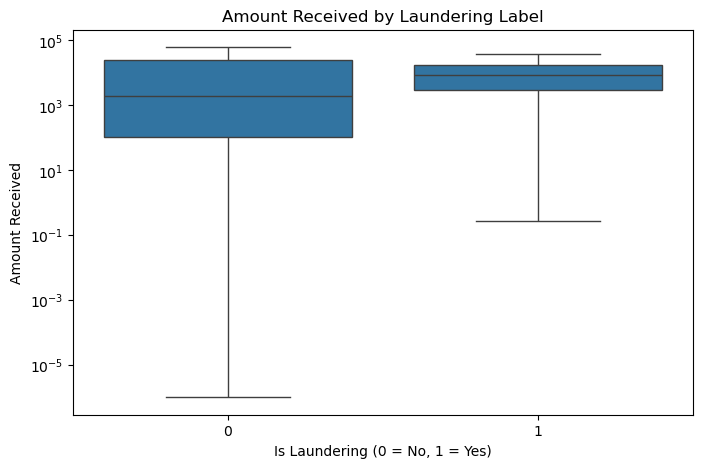

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(data = df, x = "Is Laundering", y = "Amount Paid", showfliers = False)
plt.title("Amount Received by Laundering Label")
plt.xlabel("Is Laundering (0 = No, 1 = Yes)")
plt.ylabel("Amount Received")
plt.yscale("log")
plt.show()

• Observation: The laundering group has a higher median amount. You can see its middle line sits noticeably higher up on the chart compared to the normal transactions.
• Distribution: The normal group has way more variability. Its values stretch all the way to the bottom of the graph, while the laundering amounts are tightly packed near the top.
• Evidence: Look at the lines and whiskers on your boxplot. The middle line inside the box is higher for group 1, and the total vertical span (whiskers) is much longer for group 0.
• Limitation: High value doesn't equal guilt because both boxes overlap at the top. Legitimate businesses make huge transactions every day, so flagging purely on size causes too many false alarms.

7. Which payment formats and currencies are most commonly used?

In [32]:
df.groupby("Receiving Currency").agg(currency_count=('Receiving Currency','count')).sort_values(by = "currency_count", ascending = False)

,currency_count
Receiving Currency,
US Dollar,389782
Euro,242882
Swiss Franc,48954
Yuan,43241
Shekel,40251
Rupee,39839
UK Pound,36326
Yen,32616
Ruble,32191


The top 5 receiving currencies are: US Dollar (389782), Euro (242882), Swiss Franc (48954), Yuan (43241), Shekel (40251)

In [30]:
df.groupby("Payment Currency").agg(currency_count=("Payment Currency", "count")).sort_values(by="currency_count", ascending=False)

,currency_count
Payment Currency,
US Dollar,391840
Euro,242358
Swiss Franc,48550
Yuan,44180
Shekel,39896
Rupee,39628
UK Pound,36228
Yen,32482
Ruble,31918


The top 5 payment currencies are: US Dollar	(391840), Euro (242358), Swiss Franc (48550), Yuan (44180), Shekel (39896)

In [29]:
df.groupby("Payment Format").agg(format_count=("Payment Format", "count")).sort_values(by="format_count", ascending=False)

,format_count
Payment Format,
Reinvestment,459847
Cheque,237592
Credit Card,155043
ACH,81072
Cash,61959
Bitcoin,29533
Wire,23529


The top 5 payment formats are: Reinvestment	(459847), Cheque (237592), Credit Card (155043), ACH (81072), Cash (61959)

8. How does transaction volume change over time?

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Timestamp           1048575 non-null  object 
 1   From Bank           1048575 non-null  int64  
 2   Account             1048575 non-null  object 
 3   To Bank             1048575 non-null  int64  
 4   Account.1           1048575 non-null  object 
 5   Amount Received     1048575 non-null  float64
 6   Receiving Currency  1048575 non-null  object 
 7   Amount Paid         1048575 non-null  float64
 8   Payment Currency    1048575 non-null  object 
 9   Payment Format      1048575 non-null  object 
 10  Is Laundering       1048575 non-null  int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 88.0+ MB


In [34]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   Timestamp           1048575 non-null  datetime64[ns]
 1   From Bank           1048575 non-null  int64         
 2   Account             1048575 non-null  object        
 3   To Bank             1048575 non-null  int64         
 4   Account.1           1048575 non-null  object        
 5   Amount Received     1048575 non-null  float64       
 6   Receiving Currency  1048575 non-null  object        
 7   Amount Paid         1048575 non-null  float64       
 8   Payment Currency    1048575 non-null  object        
 9   Payment Format      1048575 non-null  object        
 10  Is Laundering       1048575 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 88.0+ MB


In [37]:
monthly_volume = df.groupby(df["Timestamp"].dt.to_period('M')).agg(monthly_transactions_count = ('Amount Received', 'count'))
monthly_volume

,monthly_transactions_count
Timestamp,
2022-01,1048033
2022-02,169
2022-03,141
2022-04,140
2022-05,53
2022-06,13
2022-07,12
2022-08,11
2022-09,3


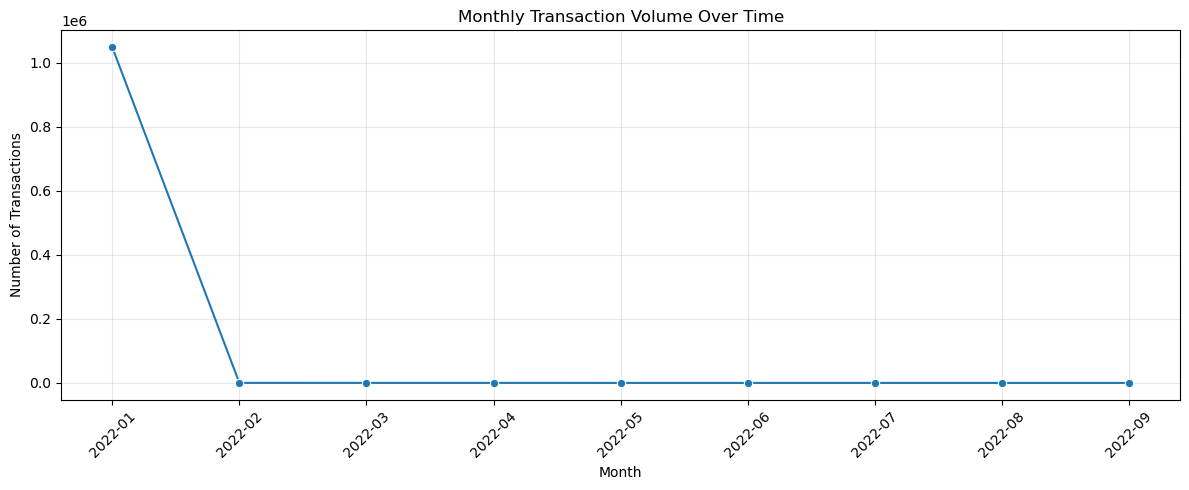

In [51]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=monthly_volume, x=monthly_volume.index.astype(str), y='monthly_transactions_count', marker='o')

plt.title('Monthly Transaction Volume Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
daily_volume = df.groupby(df["Timestamp"].dt.day_name()).agg(daily_transactions_count = ('Amount Received', 'count'))
daily_volume.sort_values(by = 'daily_transactions_count', ascending = False)

,daily_transactions_count
Timestamp,
Sunday,1048033
Wednesday,310
Saturday,152
Monday,53
Thursday,13
Tuesday,11
Friday,3


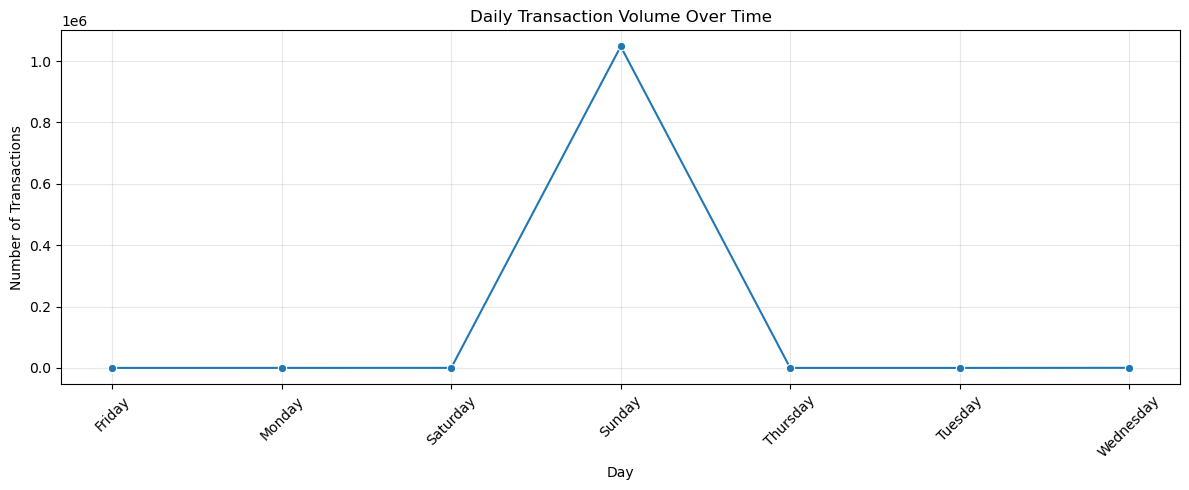

In [54]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_volume,
    x=daily_volume.index.astype(str),
    y='daily_transactions_count',
    marker='o'
)

plt.title('Daily Transaction Volume Over Time')
plt.xlabel('Day')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
hourly_volume = df.groupby(df['Timestamp'].dt.hour).agg(hourly_transaction_count=('Amount Received', 'count'))
hourly_volume.sort_values(by='Timestamp')

,hourly_transaction_count
Timestamp,
0,344216
1,33152
2,33923
3,33512
4,33326
5,33294
6,33968
7,33806
8,33096


9. Are laundering-labelled transactions more concentrated at particular hours or dates?

In [55]:
df['Hour'] = df['Timestamp'].dt.hour

In [56]:
df['Hour']

0           0
1           0
2           0
3           0
4           0
           ..
1048570    22
1048571    22
1048572    22
1048573    22
1048574    22
Name: Hour, Length: 1048575, dtype: int32

In [58]:
hourly_summary = df.groupby('Hour').agg(total_transactions = ('Is Laundering', 'count'), laundering_transactions = ('Is Laundering', 'sum'))
hourly_summary

,total_transactions,laundering_transactions
Hour,,
0,344216,32
1,33152,23
2,33923,13
3,33512,11
4,33326,15
5,33294,21
6,33968,25
7,33806,32
8,33096,35


*Calculating percentage*

In [59]:
hourly_summary['laundering_percentage'] = (hourly_summary['laundering_transactions']/ hourly_summary['total_transactions']) * 100
hourly_summary

,total_transactions,laundering_transactions,laundering_percentage
Hour,,,
0,344216,32,0.009296
1,33152,23,0.069377
2,33923,13,0.038322
3,33512,11,0.032824
4,33326,15,0.045010
5,33294,21,0.063074
6,33968,25,0.073599
7,33806,32,0.094658
8,33096,35,0.105753


In [60]:
hourly_summary.sort_values(by='laundering_percentage', ascending=False)

,total_transactions,laundering_transactions,laundering_percentage
Hour,,,
23,10,6,60.000000
22,794,2,0.251889
9,32843,39,0.118747
16,33326,39,0.117026
13,33835,39,0.115265
11,33900,39,0.115044
14,33235,37,0.111328
17,33241,36,0.108300
8,33096,35,0.105753


In [65]:
df['Timestamp'].dt.date.value_counts().sort_index().tail(10)

Timestamp
2022-01-09    1048033
2022-02-09        169
2022-03-09        141
2022-04-09        140
2022-05-09         53
2022-06-09         13
2022-07-09         12
2022-08-09         11
2022-09-09          3
Name: count, dtype: int64

**Phase 3 — Investigate potential risk indicators**

10. Which sender and receiver banks have the most laundering-labelled transactions?

In [14]:
sender_banks = df[df['Is Laundering']==1].groupby('From Bank').agg(total_transactions = ('Is Laundering','sum'))
sender_banks.sort_values(by = 'total_transactions', ascending = False).head(10)

,total_transactions
From Bank,
70,97
21174,18
213952,17
211,15
135981,14
10,14
225734,13
12,13
15,13


Key observation: Sender bank 70 has 97 laundering-labelled transactions

In [16]:
reciever_banks = df[df['Is Laundering']==1].groupby('To Bank').agg(total_transactions = ('Is Laundering','sum'))
reciever_banks.sort_values(by = 'total_transactions', ascending = False).head(10)

,total_transactions
To Bank,
12,18
48308,17
26442,16
1362,15
211,15
241869,13
20,12
135981,8
11,7


Key observation: Receiver bank 12 ranks first, with 18 laundering-labelled transactions.

11. Which accounts are involved in the highest number of laundering-labelled transactions?

In [20]:
sender_accounts = df[df['Is Laundering']==1].groupby('Account').agg(total_transactions = ('Is Laundering','sum'))
sender_accounts.sort_values(by = 'total_transactions', ascending = False).head(10)

,total_transactions
Account,
100428660,36
1004286A8,22
800737690,16
808338D40,16
80F984C70,14
808E44B10,13
8095AF170,13
80F1AF380,12
803B24460,12


In [21]:
recieving_accounts = df[df['Is Laundering']==1].groupby('Account.1').agg(total_transactions = ('Is Laundering','sum'))
recieving_accounts.sort_values(by = 'total_transactions', ascending = False).head(10)

,total_transactions
Account.1,
811ED7DF0,16
80AEBECB0,16
80F390FC0,13
808E44B10,12
8001ECD70,10
80F984C70,8
80266F880,5
811C599A0,5
812D0C3C0,5


12. Are some accounts transacting with unusually many different counterparties?

In [25]:
top_senders = df.groupby('Account').agg(unique_receivers=('Account.1', 'nunique')).sort_values(by='unique_receivers', ascending=False)
top_senders.head(10)

,unique_receivers
Account,
100428660,10064
1004286A8,6169
100428978,1250
1004286F0,1125
100428780,1006
1004289C0,1004
100428810,997
1004287C8,819
100428738,806


In [33]:
top_receivers = df.groupby('Account.1').agg(unique_senders=('Account', 'nunique')).sort_values(by='unique_senders', ascending=False)
top_receivers.head(10)

,unique_senders
Account.1,
8.01E+06,151
8.08E+06,144
8.04E+06,135
8.09E+06,132
8.06E+06,127
8.07E+06,124
8.10E+06,121
8.11E+06,121
8.05E+06,117


**Phase 4 — Summarise your findings**

13. What are the 3–5 most important insights from the analysis, and what additional investigation would you recommend?

**Key Findings from EDA**

After exploring the transaction data, I identified a few patterns worth looking into further.

**1. Laundering-labelled transactions are very rare**

Only **0.0587% of transactions** are labelled as laundering, while the remaining **99.9413%** are labelled as non-laundering. This shows a significant imbalance in the dataset. It also means that simply predicting every transaction as non-laundering could produce high accuracy while failing to identify the transactions we actually want to detect.

**2. Transaction amounts have many potential outliers**

Around **18.82% of Amount Received values** and **18.80% of Amount Paid values** fall above their respective IQR-based upper bounds. This suggests that unusually large values are fairly common in the analysed data. However, a transaction being an outlier does not automatically make it suspicious, so these values need to be examined in context.

**3. Laundering-labelled transactions show higher median amounts**

The boxplots suggest that transactions labelled as laundering have higher median amounts received and paid than non-laundering transactions. Transaction amount may therefore be a useful factor to investigate when studying potential risk patterns. However, amount alone is not enough to determine whether a transaction is suspicious.

**4. Some payment formats and currencies are more common than others**

Reinvestment and cheque are the most frequent payment formats in the analysed data, with **459,847** and **237,592** transactions, respectively. US Dollar and Euro are the most common receiving currencies, with **389,782** and **242,882** transactions, respectively.

These counts show which categories account for a large share of transaction activity. The next step is to compare laundering rates across these categories to see whether any meaningful differences emerge.

**5. Some banks and accounts appear repeatedly in laundering-labelled transactions**

Sender bank **70** has the highest observed count of laundering-labelled transactions (**97**), while receiver bank **12** has the highest observed count on the receiving side (**18**). Some sender accounts also appear repeatedly in transactions labelled as laundering.

These patterns make the banks and accounts worth investigating further. Looking at their transaction histories and connections with other accounts may help reveal patterns that are not visible from individual transactions alone.

**Overall takeaway**

This initial analysis highlights three areas worth exploring further: the imbalance between laundering-labelled and non-laundering transactions, differences in transaction amounts, and repeated activity involving certain payment categories and entities. These are exploratory findings, not proof of actual money laundering. Further analysis using SQL will help investigate these patterns in greater detail.